## Importing Dataset

In [120]:
import pandas as pd
from pathlib import Path

# Define the project root
PROJECT_ROOT = Path.cwd().parent

# Define the raw data path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "project_dataset_combined.csv"

# Load the raw dataset
df = pd.read_csv(DATA_PATH)

# Display the first 5 rows
df.head()

,Emp ID,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,dept,salary,Attrition
0,1,0.38,0.53,2,157,3,0,0,sales,low,yes
1,2,0.80,0.86,5,262,6,0,0,sales,medium,yes
2,3,0.11,0.88,7,272,4,0,0,sales,medium,yes
3,4,0.72,0.87,5,223,5,0,0,sales,low,yes
4,5,0.37,0.52,2,159,3,0,0,sales,low,yes


In [121]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 14999
Columns: 11

Column names:
['Emp ID', 'satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years', 'dept', 'salary', 'Attrition']


## DATA QUALITY CHECK

Data types and Missing Values

In [122]:
print("DATA TYPES")
print(df.dtypes)

print("\n" + "=" * 60)
print("MISSING VALUES")
print(df.isna().sum())

print("\n" + "=" * 60)
print("DUPLICATE ROWS")
print(df.duplicated().sum())

DATA TYPES
Emp ID                     int64
satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
promotion_last_5years      int64
dept                         str
salary                       str
Attrition                    str
dtype: object

MISSING VALUES
Emp ID                   0
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
promotion_last_5years    0
dept                     0
salary                   0
Attrition                0
dtype: int64

DUPLICATE ROWS
0


Examining Categorical Values

In [123]:
print("DEPARTMENTS")
print(df["dept"].value_counts())

print("\n" + "=" * 60)
print("SALARY LEVELS")
print(df["salary"].value_counts())

print("\n" + "=" * 60)
print("ATTRITION VALUES")
print(df["Attrition"].value_counts())

DEPARTMENTS
dept
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64

SALARY LEVELS
salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64

ATTRITION VALUES
Attrition
no     11428
yes     3571
Name: count, dtype: int64


Checking Numerical Variables

In [124]:
numeric_cols = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company",
    "Work_accident",
    "promotion_last_5years"
]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803054,1.232592,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050337,49.943099,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498233,1.460136,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.144610,0.351719,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021268,0.144281,0.00,0.00,0.00,0.00,1.0


Checking Binary Values

In [125]:
binary_cols = [
    "Work_accident",
    "promotion_last_5years"
]

for col in binary_cols:
    print(f"\n{col}")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).mul(100).round(2))


Work_accident
Work_accident
0    12830
1     2169
Name: count, dtype: int64
Work_accident
0    85.54
1    14.46
Name: proportion, dtype: float64

promotion_last_5years
promotion_last_5years
0    14680
1      319
Name: count, dtype: int64
promotion_last_5years
0    97.87
1     2.13
Name: proportion, dtype: float64


Checking EmployeeID for Uniqueness

In [126]:
print("Total rows:", len(df))
print("Unique Employee IDs:", df["Emp ID"].nunique())

print("\nDuplicate Employee IDs:", df["Emp ID"].duplicated().sum())

print("\nEmployee ID range:")
print("Minimum:", df["Emp ID"].min())
print("Maximum:", df["Emp ID"].max())

Total rows: 14999
Unique Employee IDs: 14999

Duplicate Employee IDs: 0

Employee ID range:
Minimum: 1
Maximum: 14999


Checking Categorical Values

In [127]:
categorical_cols = [
    "dept",
    "salary",
    "Attrition"
]

for col in categorical_cols:
    print(f"\n{'=' * 60}")
    print(f"{col} — unique values")
    print(df[col].unique())

    print(f"\nNumber of unique values: {df[col].nunique()}")


dept — unique values
<StringArray>
[      'sales',  'accounting',          'hr',   'technical',     'support',
  'management',          'IT', 'product_mng',   'marketing',       'RandD']
Length: 10, dtype: str

Number of unique values: 10

salary — unique values
<StringArray>
['low', 'medium', 'high']
Length: 3, dtype: str

Number of unique values: 3

Attrition — unique values
<StringArray>
['yes', 'no']
Length: 2, dtype: str

Number of unique values: 2


Analysis Dataset

In [128]:
# Create a working copy for analysis
df_analysis = df.copy()

# Standardize text fields
df_analysis["dept"] = df_analysis["dept"].str.strip()
df_analysis["salary"] = df_analysis["salary"].str.strip().str.lower()
df_analysis["Attrition"] = df_analysis["Attrition"].str.strip().str.lower()

# Create numeric target for analysis/modeling
df_analysis["attrition_flag"] = (
    df_analysis["Attrition"].map({"yes": 1, "no": 0})
)

# Verify the transformation
print(df_analysis[["Attrition", "attrition_flag"]].value_counts())

print("\nMissing values in attrition_flag:")
print(df_analysis["attrition_flag"].isna().sum())

Attrition  attrition_flag
no         0                 11428
yes        1                  3571
Name: count, dtype: int64

Missing values in attrition_flag:
0


## EDA

Overall Attrition

In [129]:
attrition_summary = (
    df_analysis["Attrition"]
    .value_counts()
    .rename_axis("Attrition")
    .reset_index(name="Employees")
)

attrition_summary["Percentage"] = (
    attrition_summary["Employees"]
    / len(df_analysis)
    * 100
).round(2)

attrition_summary

,Attrition,Employees,Percentage
0,no,11428,76.19
1,yes,3571,23.81


In [130]:
attrition_rate = df_analysis["attrition_flag"].mean() * 100

print(f"Overall attrition rate: {attrition_rate:.2f}%")

Overall attrition rate: 23.81%


Attrition BY Department

In [131]:
dept_attrition = (
    pd.crosstab(
        df_analysis["dept"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

dept_attrition["Total Employees"] = df_analysis["dept"].value_counts()

dept_attrition = dept_attrition.sort_values(
    "yes",
    ascending=False
)

dept_attrition

Attrition,no,yes,Total Employees
dept,,,
hr,70.91,29.09,739
accounting,73.40,26.60,767
technical,74.38,25.62,2720
support,75.10,24.90,2229
sales,75.51,24.49,4140
marketing,76.34,23.66,858
IT,77.75,22.25,1227
product_mng,78.05,21.95,902
RandD,84.63,15.37,787


Visualization

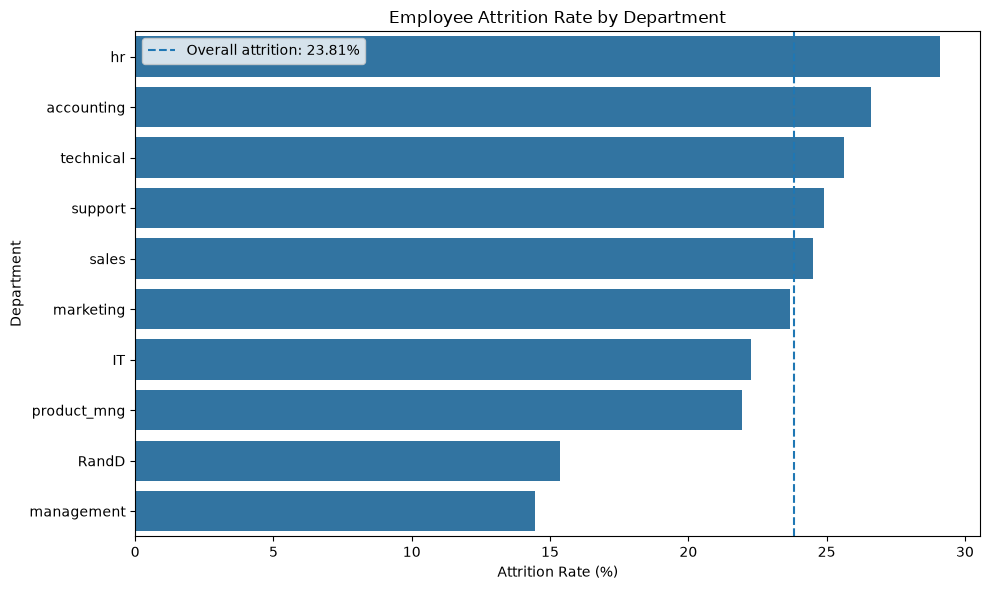

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=dept_attrition.reset_index(),
    x="yes",
    y="dept"
)

plt.axvline(
    attrition_rate,
    linestyle="--",
    label=f"Overall attrition: {attrition_rate:.2f}%"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.legend()
plt.tight_layout()
plt.show()

Attrition BY Salary Level

In [133]:
salary_attrition = (
    pd.crosstab(
        df_analysis["salary"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

salary_attrition["Total Employees"] = df_analysis["salary"].value_counts()

salary_attrition = salary_attrition.sort_values(
    "yes",
    ascending=False
)

salary_attrition

Attrition,no,yes,Total Employees
salary,,,
low,70.31,29.69,7316
medium,79.57,20.43,6446
high,93.37,6.63,1237


Visualization

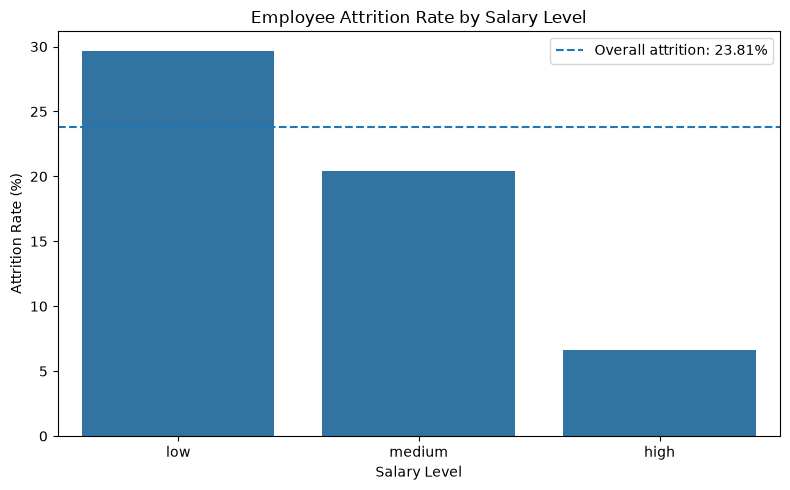

In [134]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=salary_attrition.reset_index(),
    x="salary",
    y="yes"
)

plt.axhline(
    attrition_rate,
    linestyle="--",
    label=f"Overall attrition: {attrition_rate:.2f}%"
)

plt.title("Employee Attrition Rate by Salary Level")
plt.xlabel("Salary Level")
plt.ylabel("Attrition Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

Attrition varies substantially across salary levels, with the highest observed attrition rate among low-salary employees and the lowest among high-salary employees.

Satisfaction Level

In [135]:
satisfaction_summary = (
    df_analysis
    .groupby("Attrition")["satisfaction_level"]
    .agg(["count", "mean", "median"])
    .round(3)
)

satisfaction_summary

,count,mean,median
Attrition,,,
no,11428,0.667,0.69
yes,3571,0.440,0.41


Visualization

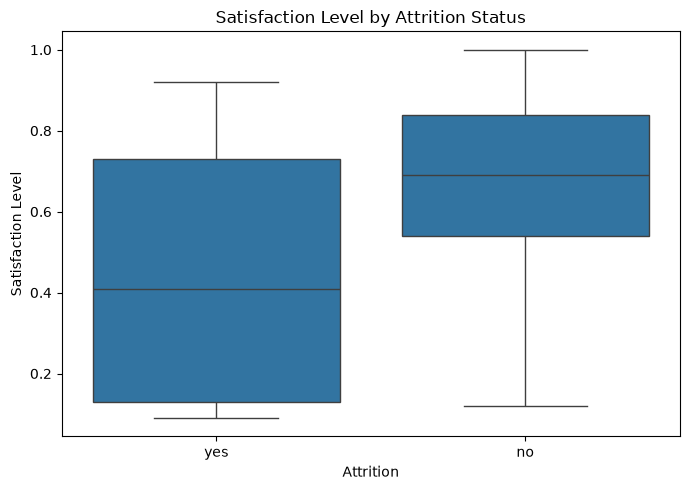

In [136]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="satisfaction_level"
)

plt.title("Satisfaction Level by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Satisfaction Level")
plt.tight_layout()
plt.show()

Employees who left had considerably lower satisfaction levels than employees who remained, indicating a strong association between satisfaction and observed attrition.

Workload & Performance

In [137]:
workload_summary = (
    df_analysis
    .groupby("Attrition")[
        [
            "last_evaluation",
            "number_project",
            "average_montly_hours",
            "time_spend_company"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

workload_summary

last_evaluation        number_project        average_montly_hours  \
                     mean median           mean median                 mean   
Attrition                                                                     
no                   0.72   0.71           3.79    4.0               199.06   
yes                  0.72   0.79           3.86    4.0               207.42   

                 time_spend_company         
          median               mean median  
Attrition                                   
no         198.0               3.38    3.0  
yes        224.0               3.88    4.0

Visualization

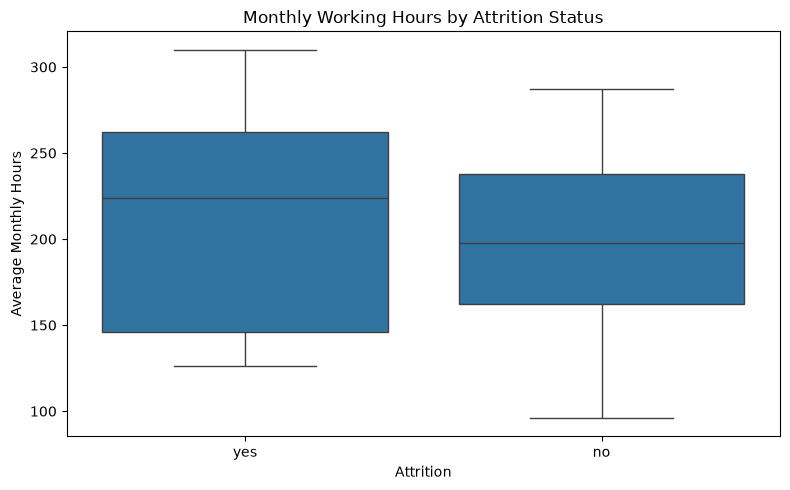

In [138]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="average_montly_hours"
)

plt.title("Monthly Working Hours by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Average Monthly Hours")

plt.tight_layout()
plt.show()

Workload Pattern

In [139]:
hours_groups = pd.cut(
    df_analysis["average_montly_hours"],
    bins=[0, 160, 200, 240, 280, float("inf")],
    labels=["≤160", "161–200", "201–240", "241–280", "281+"]
)

hours_attrition = (
    pd.crosstab(
        hours_groups,
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

hours_attrition["Total Employees"] = hours_groups.value_counts().sort_index()

hours_attrition

Attrition,no,yes,Total Employees
average_montly_hours,,,
≤160,63.73,36.27,4340
161–200,97.42,2.58,3184
201–240,87.94,12.06,3267
241–280,70.71,29.29,3646
281+,19.40,80.60,562


Visualization

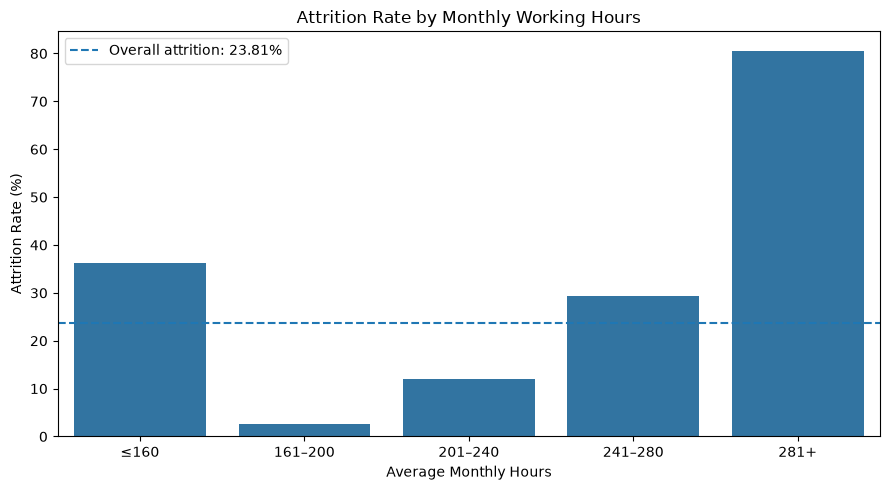

In [140]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=hours_attrition.reset_index(),
    x="average_montly_hours",
    y="yes"
)

plt.axhline(
    attrition_rate,
    linestyle="--",
    label=f"Overall attrition: {attrition_rate:.2f}%"
)

plt.title("Attrition Rate by Monthly Working Hours")
plt.xlabel("Average Monthly Hours")
plt.ylabel("Attrition Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

Number Of Projects

In [141]:
project_attrition = (
    pd.crosstab(
        df_analysis["number_project"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

project_attrition["Total Employees"] = (
    df_analysis["number_project"].value_counts().sort_index()
)

project_attrition

Attrition,no,yes,Total Employees
number_project,,,
2,34.38,65.62,2388
3,98.22,1.78,4055
4,90.63,9.37,4365
5,77.83,22.17,2761
6,44.21,55.79,1174
7,0.00,100.00,256


Visualization

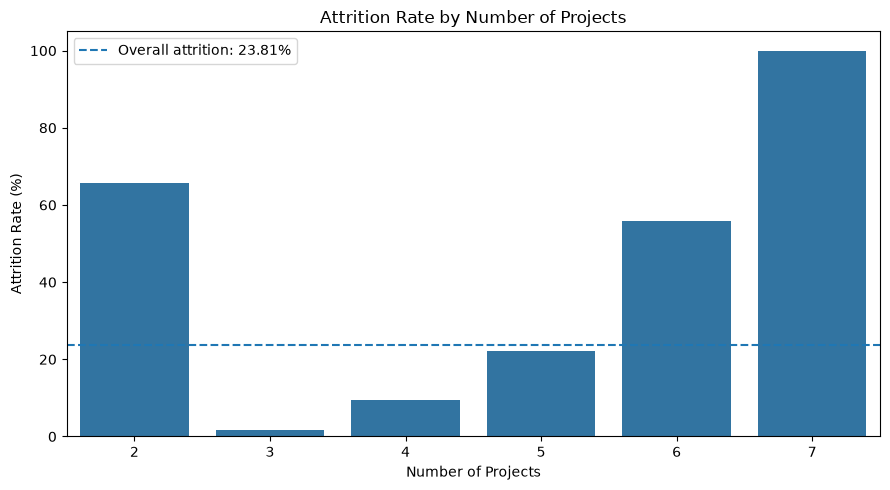

In [142]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=project_attrition.reset_index(),
    x="number_project",
    y="yes"
)

plt.axhline(
    attrition_rate,
    linestyle="--",
    label=f"Overall attrition: {attrition_rate:.2f}%"
)

plt.title("Attrition Rate by Number of Projects")
plt.xlabel("Number of Projects")
plt.ylabel("Attrition Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

Tenure

In [143]:
tenure_attrition = (
    pd.crosstab(
        df_analysis["time_spend_company"],
        df_analysis["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

tenure_attrition["Total Employees"] = (
    df_analysis["time_spend_company"].value_counts().sort_index()
)

tenure_attrition

Attrition,no,yes,Total Employees
time_spend_company,,,
2,98.37,1.63,3244
3,75.38,24.62,6443
4,65.19,34.81,2557
5,43.45,56.55,1473
6,70.89,29.11,718
7,100.00,0.00,188
8,100.00,0.00,162
10,100.00,0.00,214


Visualization

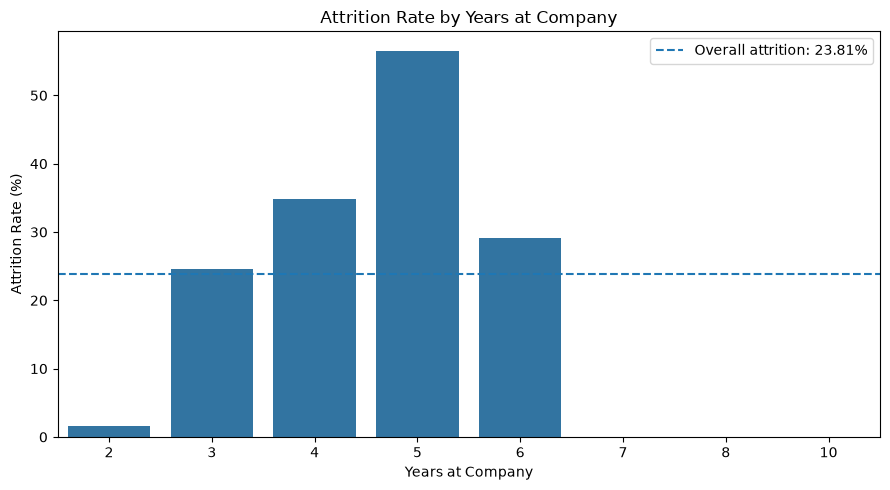

In [144]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_attrition.reset_index(),
    x="time_spend_company",
    y="yes"
)

plt.axhline(
    attrition_rate,
    linestyle="--",
    label=f"Overall attrition: {attrition_rate:.2f}%"
)

plt.title("Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

## STATISTICAL ANALYSIS

In [145]:
from scipy.stats import chi2_contingency

categorical_tests = [
    "dept",
    "salary",
    "Work_accident",
    "promotion_last_5years"
]

chi_square_results = []

for col in categorical_tests:
    contingency_table = pd.crosstab(
        df_analysis[col],
        df_analysis["Attrition"]
    )

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    chi_square_results.append({
        "Variable": col,
        "Chi2": chi2,
        "p_value": p_value,
        "Degrees_of_freedom": dof
    })

chi_square_results = pd.DataFrame(chi_square_results)

chi_square_results

,Variable,Chi2,p_value,Degrees_of_freedom
0,dept,86.825474,7.042130e-15,9
1,salary,381.225047,1.652087e-83,2
2,Work_accident,357.562360,9.558240e-80,1
3,promotion_last_5years,56.261627,6.344155e-14,1


Statistical significance tells us that the distributions differ; it does not tell us that these variables cause employees to leave.

Cramér's V:

In [146]:
import numpy as np

cramers_v_results = []

for col in categorical_tests:
    contingency_table = pd.crosstab(
        df_analysis[col],
        df_analysis["Attrition"]
    )

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    phi2 = chi2 / n

    # Bias-corrected Cramér's V
    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    cols_corrected = cols - ((cols - 1) ** 2) / (n - 1)

    cramers_v = np.sqrt(
        phi2_corrected /
        min(rows_corrected - 1, cols_corrected - 1)
    )

    cramers_v_results.append({
        "Variable": col,
        "Chi2": chi2,
        "p_value": p_value,
        "Cramers_V": cramers_v
    })

cramers_v_results = pd.DataFrame(cramers_v_results)

cramers_v_results.sort_values(
    "Cramers_V",
    ascending=False
).round(4)

,Variable,Chi2,p_value,Cramers_V
1,salary,381.2250,0.0,0.1590
2,Work_accident,357.5624,0.0,0.1542
0,dept,86.8255,0.0,0.0720
3,promotion_last_5years,56.2616,0.0,0.0607


Testing Numeric Variables

In [147]:
from scipy.stats import mannwhitneyu

numeric_test_cols = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company"
]

numeric_test_results = []

for col in numeric_test_cols:
    stayed = df_analysis.loc[
        df_analysis["attrition_flag"] == 0,
        col
    ]

    left = df_analysis.loc[
        df_analysis["attrition_flag"] == 1,
        col
    ]

    statistic, p_value = mannwhitneyu(
        stayed,
        left,
        alternative="two-sided"
    )

    numeric_test_results.append({
        "Variable": col,
        "Stayed_Median": stayed.median(),
        "Left_Median": left.median(),
        "Mann_Whitney_U": statistic,
        "p_value": p_value
    })

numeric_test_results = pd.DataFrame(numeric_test_results)

numeric_test_results.round(4)

,Variable,Stayed_Median,Left_Median,Mann_Whitney_U,p_value
0,satisfaction_level,0.69,0.41,30522915.0,0.0000
1,last_evaluation,0.71,0.79,20472187.0,0.7650
2,number_project,4.00,4.00,20930147.0,0.0167
3,average_montly_hours,198.00,224.00,19119787.5,0.0000
4,time_spend_company,3.00,4.00,13331224.0,0.0000


## Creating Modelling Dataset

In [148]:
# Define model features
feature_cols = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company",
    "Work_accident",
    "promotion_last_5years",
    "dept",
    "salary"
]

target_col = "attrition_flag"

# Create modeling dataset
X = df_analysis[feature_cols].copy()
y = df_analysis[target_col].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Feature matrix shape: (14999, 9)
Target shape: (14999,)

Features:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years', 'dept', 'salary']

Target distribution:
attrition_flag
0    11428
1     3571
Name: count, dtype: int64

Target percentage:
attrition_flag
0    76.19
1    23.81
Name: proportion, dtype: float64


TEST/TRAIN SPLIT

In [149]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTest set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTest target distribution:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training set:
X_train: (11999, 9)
y_train: (11999,)

Test set:
X_test: (3000, 9)
y_test: (3000,)

Training target distribution:
attrition_flag
0    76.19
1    23.81
Name: proportion, dtype: float64

Test target distribution:
attrition_flag
0    76.2
1    23.8
Name: proportion, dtype: float64


Building PREPROCESSING Pipeline

In [150]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company",
    "Work_accident",
    "promotion_last_5years"
]

categorical_features = [
    "dept",
    "salary"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nPreprocessor created successfully.")

Numeric features:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']

Categorical features:
['dept', 'salary']

Preprocessor created successfully.


Creating Logistic Regression Pipeline

In [151]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


Fitting The Model

In [152]:
# Fit the Logistic Regression pipeline on the training data
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


Generating Predictions

In [153]:
# Generate class predictions
y_pred = logistic_pipeline.predict(X_test)

# Generate probability predictions for the positive class (attrition = 1)
y_pred_proba = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 class predictions:")
print(y_pred[:10])

print("\nFirst 10 attrition probabilities:")
print(y_pred_proba[:10])

Predictions generated successfully.

First 10 class predictions:
[0 0 0 0 0 0 0 1 0 0]

First 10 attrition probabilities:
[0.07566454 0.06443888 0.27978934 0.04219538 0.02577457 0.32736003
 0.17909122 0.52316405 0.32838789 0.216665  ]


Evaluating Logistic Regression Model

In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)
pr_auc = average_precision_score(y_test, y_pred_proba)

# Display results
print("LOGISTIC REGRESSION — TEST SET PERFORMANCE")
print("=" * 55)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

LOGISTIC REGRESSION — TEST SET PERFORMANCE
Accuracy:  0.7943
Precision: 0.6186
Recall:    0.3543
F1 Score:  0.4506
ROC-AUC:   0.8280
PR-AUC:    0.5342


Confusion Matrix

CONFUSION MATRIX
[[2130  156]
 [ 461  253]]


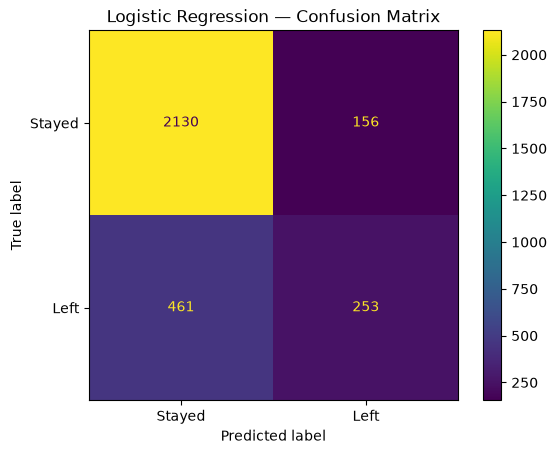

In [155]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX")
print("=" * 40)
print(cm)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

disp.plot()
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

Classification Report

In [156]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION — CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Left"],
        digits=4
    )
)

LOGISTIC REGRESSION — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed     0.8221    0.9318    0.8735      2286
        Left     0.6186    0.3543    0.4506       714

    accuracy                         0.7943      3000
   macro avg     0.7203    0.6431    0.6620      3000
weighted avg     0.7736    0.7943    0.7728      3000



The model's ROC-AUC of 0.828 tells us that the underlying probability ranking contains useful information, even though the default 0.50 threshold produces only 35.4% recall.

Inspecting Logistic Regression coefficients

In [157]:
# Get the fitted preprocessing step
fitted_preprocessor = logistic_pipeline.named_steps["preprocessor"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_pipeline.named_steps["model"].coef_[0]

# Create a dataframe of coefficients
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Add absolute coefficient size for sorting
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

# Sort by absolute coefficient size
coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coef_df

,Feature,Coefficient,Abs_Coefficient
16,cat__salary_low,1.801093,1.801093
17,cat__salary_medium,1.267657,1.267657
0,num__satisfaction_level,-1.022096,1.022096
5,num__Work_accident,-0.534987,0.534987
9,cat__dept_hr,0.498312,0.498312
7,cat__dept_RandD,-0.434388,0.434388
2,num__number_project,-0.394939,0.394939
4,num__time_spend_company,0.391717,0.391717
10,cat__dept_management,-0.266220,0.266220
15,cat__dept_technical,0.263920,0.263920


Salary category and satisfaction level showed the largest coefficient magnitudes in the baseline Logistic Regression model, with lower salary categories and lower satisfaction associated with higher predicted attrition risk.

RANDOM FOREST MODEL

Logistic Regression gives us interpretability and a linear baseline. Random Forest will let us test whether a non-linear tree-based model can capture more complex relationships.

Creating The Pipeline:

In [158]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


Fitting The Model

In [159]:
# Fit the Random Forest pipeline on the training data
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model fitted successfully.")

Random Forest model fitted successfully.


Generating Random Forest Predictions

In [160]:
# Generate Random Forest class predictions
rf_y_pred = random_forest_pipeline.predict(X_test)

# Generate Random Forest probability predictions
rf_y_pred_proba = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully.")

print("\nFirst 10 class predictions:")
print(rf_y_pred[:10])

print("\nFirst 10 attrition probabilities:")
print(rf_y_pred_proba[:10])

Random Forest predictions generated successfully.

First 10 class predictions:
[0 0 0 0 0 0 0 1 0 0]

First 10 attrition probabilities:
[0.00666667 0.         0.00666667 0.         0.         0.02666667
 0.14666667 1.         0.05666667 0.01      ]


Random Forest Performance

In [161]:
# Calculate Random Forest evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
rf_roc_auc = roc_auc_score(y_test, rf_y_pred_proba)
rf_pr_auc = average_precision_score(y_test, rf_y_pred_proba)

# Display results
print("RANDOM FOREST — TEST SET PERFORMANCE")
print("=" * 55)
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")
print(f"PR-AUC:    {rf_pr_auc:.4f}")

RANDOM FOREST — TEST SET PERFORMANCE
Accuracy:  0.9907
Precision: 0.9957
Recall:    0.9650
F1 Score:  0.9801
ROC-AUC:   0.9912
PR-AUC:    0.9880


This result is so much stronger than the Logistic Regression baseline that we need to investigate whether the Random Forest is genuinely capturing non-linear structure or whether there is a methodological/data issue.

Random Forest Confusion Matrix

RANDOM FOREST — CONFUSION MATRIX
[[2283    3]
 [  25  689]]


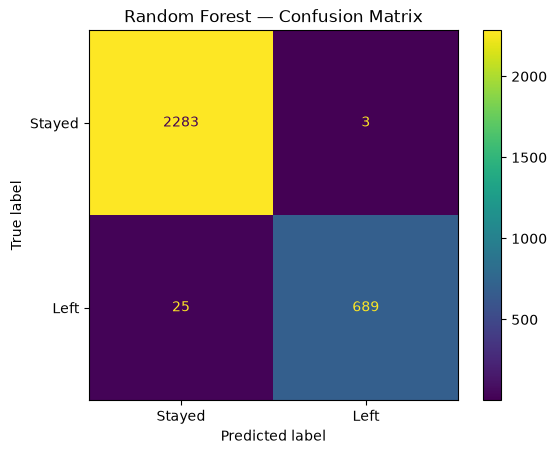

In [162]:
# Random Forest confusion matrix
rf_cm = confusion_matrix(y_test, rf_y_pred)

print("RANDOM FOREST — CONFUSION MATRIX")
print("=" * 45)
print(rf_cm)

# Display the confusion matrix
rf_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Stayed", "Left"]
)

rf_disp.plot()
plt.title("Random Forest — Confusion Matrix")
plt.show()

Comparing Training VS Test Performance

In [163]:
# Generate predictions on the training data
rf_train_pred = random_forest_pipeline.predict(X_train)

# Calculate training accuracy
rf_train_accuracy = accuracy_score(y_train, rf_train_pred)

# Calculate test accuracy
rf_test_accuracy = accuracy_score(y_test, rf_y_pred)

print("RANDOM FOREST — TRAIN vs TEST")
print("=" * 45)
print(f"Training accuracy: {rf_train_accuracy:.4f}")
print(f"Test accuracy:     {rf_test_accuracy:.4f}")
print(f"Accuracy gap:      {rf_train_accuracy - rf_test_accuracy:.4f}")

RANDOM FOREST — TRAIN vs TEST
Training accuracy: 1.0000
Test accuracy:     0.9907
Accuracy gap:      0.0093


Cross-Validating The Random Forest

In [164]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(
    random_forest_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("RANDOM FOREST — 5-FOLD CROSS-VALIDATION")
print("=" * 50)

for i, score in enumerate(rf_cv_scores, start=1):
    print(f"Fold {i}: ROC-AUC = {score:.4f}")

print("-" * 50)
print(f"Mean ROC-AUC: {rf_cv_scores.mean():.4f}")
print(f"Std. deviation: {rf_cv_scores.std():.4f}")

RANDOM FOREST — 5-FOLD CROSS-VALIDATION
Fold 1: ROC-AUC = 0.9919
Fold 2: ROC-AUC = 0.9931
Fold 3: ROC-AUC = 0.9939
Fold 4: ROC-AUC = 0.9961
Fold 5: ROC-AUC = 0.9945
--------------------------------------------------
Mean ROC-AUC: 0.9939
Std. deviation: 0.0014


Random Forest's high performance exhibits stability within this dataset.

Which employee characteristics contribute most to the Random Forest's predictions?

In [165]:
# Extract the fitted preprocessing step
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

# Get transformed feature names
rf_feature_names = rf_preprocessor.get_feature_names_out()

# Get Random Forest feature importances
rf_importances = random_forest_pipeline.named_steps["model"].feature_importances_

# Create feature importance table
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Sort from highest to lowest
rf_importance_df = rf_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

rf_importance_df

,Feature,Importance
0,num__satisfaction_level,0.315829
1,num__time_spend_company,0.186686
2,num__number_project,0.183009
3,num__average_montly_hours,0.149373
4,num__last_evaluation,0.123497
5,num__Work_accident,0.009779
6,cat__salary_low,0.007973
7,cat__salary_medium,0.003782
8,cat__dept_technical,0.003537
9,cat__dept_sales,0.003393


In [166]:
print("TOP 15 RANDOM FOREST FEATURES")
print("=" * 50)

display(
    rf_importance_df.head(15)
)

TOP 15 RANDOM FOREST FEATURES


,Feature,Importance
0,num__satisfaction_level,0.315829
1,num__time_spend_company,0.186686
2,num__number_project,0.183009
3,num__average_montly_hours,0.149373
4,num__last_evaluation,0.123497
5,num__Work_accident,0.009779
6,cat__salary_low,0.007973
7,cat__salary_medium,0.003782
8,cat__dept_technical,0.003537
9,cat__dept_sales,0.003393


Five numerical variables account for about 97.1% of the total Random Forest importance. relying predominantly on: 
Satisfaction, Tenure, Project workload, Monthly working hours, Last evaluation

PERMUTATION IMPORTANCE: How much does model performance deteriorate when we randomly scramble one feature?

In [167]:
from sklearn.inspection import permutation_importance

rf_permutation = permutation_importance(
    random_forest_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": rf_permutation.importances_mean,
    "Importance_STD": rf_permutation.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST — PERMUTATION IMPORTANCE")
print("=" * 55)

display(permutation_df)

RANDOM FOREST — PERMUTATION IMPORTANCE


,Feature,Importance_Mean,Importance_STD
0,satisfaction_level,0.106151,0.003198
1,time_spend_company,0.062174,0.002405
2,number_project,0.045965,0.001836
3,average_montly_hours,0.021433,0.001731
4,last_evaluation,0.013659,0.001570
5,dept,0.000670,0.000686
6,salary,0.000437,0.000720
7,Work_accident,0.000183,0.000299
8,promotion_last_5years,0.000049,0.000091


Across both impurity-based and permutation-based Random Forest importance measures, satisfaction level, time spent at the company, number of projects, monthly working hours, and last evaluation were the five most influential predictors in the model.

## FINAL MODELLING STAGE

Inspecting Probability Distribution

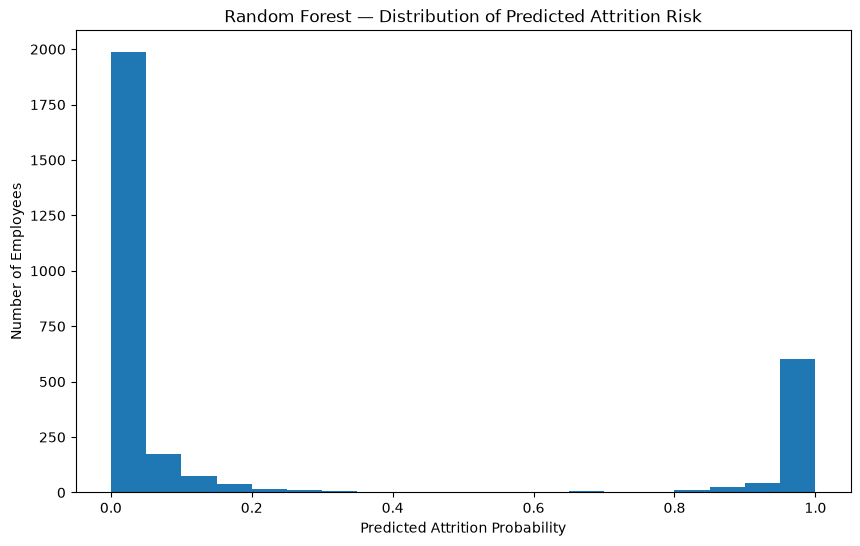

In [168]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    rf_y_pred_proba,
    bins=20
)

plt.xlabel("Predicted Attrition Probability")
plt.ylabel("Number of Employees")
plt.title("Random Forest — Distribution of Predicted Attrition Risk")

plt.show()

Inspecting Probabilities

In [169]:
# Examine the predicted probability distribution numerically

probability_summary = pd.Series(rf_y_pred_proba).describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("RANDOM FOREST — PREDICTED PROBABILITY SUMMARY")
print("=" * 55)
print(probability_summary)

RANDOM FOREST — PREDICTED PROBABILITY SUMMARY
count    3000.000000
mean        0.243573
std         0.404830
min         0.000000
1%          0.000000
5%          0.000000
10%         0.000000
25%         0.000000
50%         0.013333
75%         0.166667
90%         1.000000
95%         1.000000
99%         1.000000
max         1.000000
dtype: float64


In [170]:
# Count predictions by probability range

probability_bins = pd.cut(
    rf_y_pred_proba,
    bins=[-0.001, 0.10, 0.25, 0.50, 0.75, 0.90, 1.001],
    labels=[
        "0–10%",
        "10–25%",
        "25–50%",
        "50–75%",
        "75–90%",
        "90–100%"
    ]
)

probability_counts = probability_bins.value_counts().sort_index()

print("PREDICTED ATTRITION PROBABILITY BANDS")
print("=" * 55)
print(probability_counts)

PREDICTED ATTRITION PROBABILITY BANDS
0–10%      2161
10–25%      125
25–50%       22
50–75%       14
75–90%       37
90–100%     641
Name: count, dtype: int64


Calibration Analysis

In [171]:
from sklearn.calibration import calibration_curve

# Calculate observed attrition rate within probability bins
prob_true, prob_pred = calibration_curve(
    y_test,
    rf_y_pred_proba,
    n_bins=10,
    strategy="quantile"
)

calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": prob_pred,
    "Observed_Attrition_Rate": prob_true
})

print("RANDOM FOREST — CALIBRATION")
print("=" * 60)

display(calibration_df)

RANDOM FOREST — CALIBRATION


,Mean_Predicted_Probability,Observed_Attrition_Rate
0,0.000000,0.003690
1,0.003333,0.011905
2,0.006667,0.000000
3,0.011352,0.004608
4,0.021116,0.000000
5,0.045507,0.020067
6,0.372872,0.341216
7,0.994417,0.998333


The Random Forest demonstrated very strong discrimination and produced highly separated predicted-risk groups. Calibration was strongest among the higher-risk groups, while the very low-risk probability estimates should not be interpreted as precise individual probabilities.

Threshold Analysis

In [172]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:
    threshold_pred = (rf_y_pred_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1": f1_score(y_test, threshold_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print("RANDOM FOREST — THRESHOLD ANALYSIS")
print("=" * 65)

display(threshold_df)

RANDOM FOREST — THRESHOLD ANALYSIS


,Threshold,Precision,Recall,F1
0,0.1,0.826809,0.976190,0.895311
1,0.2,0.950617,0.970588,0.960499
2,0.3,0.981560,0.969188,0.975335
3,0.4,0.989957,0.966387,0.978030
4,0.5,0.995665,0.964986,0.980085
5,0.6,0.995646,0.960784,0.977904
6,0.7,0.995575,0.945378,0.969828
7,0.8,0.995569,0.943978,0.969087
8,0.9,0.996885,0.896359,0.943953


Lowering the threshold to 0.10 catches more potential leavers: recall rises to 97.62%, but precision falls to 82.68%.
At 0.20, we retain 97.06% recall while precision rises to 95.06%.
From 0.30–0.60, precision remains around 98–99.6% while recall remains above 96%.
Increasing the threshold beyond 0.50 produces only small precision gains but increasingly sacrifices recall.

Building Model Output Table

In [173]:
# Create an employee-level model output table for the test set

model_output = X_test.copy()

model_output["Emp ID"] = df_analysis.loc[X_test.index, "Emp ID"]
model_output["Actual_Attrition"] = y_test
model_output["Predicted_Attrition"] = rf_y_pred
model_output["Predicted_Probability"] = rf_y_pred_proba

# Create a simple risk classification using the baseline 0.50 threshold
model_output["Risk_Class"] = np.where(
    model_output["Predicted_Probability"] >= 0.50,
    "Higher predicted risk",
    "Lower predicted risk"
)

# Reorder columns
model_output = model_output[
    [
        "Emp ID",
        "satisfaction_level",
        "last_evaluation",
        "number_project",
        "average_montly_hours",
        "time_spend_company",
        "Work_accident",
        "promotion_last_5years",
        "dept",
        "salary",
        "Actual_Attrition",
        "Predicted_Attrition",
        "Predicted_Probability",
        "Risk_Class"
    ]
].sort_values(
    "Predicted_Probability",
    ascending=False
)

display(model_output.head(20))

,Emp ID,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,dept,salary,Actual_Attrition,Predicted_Attrition,Predicted_Probability,Risk_Class
330,331,0.38,0.57,2,140,3,0,0,sales,low,1,1,1.0,Higher predicted risk
14232,14233,0.38,0.55,2,147,3,0,0,sales,low,1,1,1.0,Higher predicted risk
12395,12396,0.45,0.46,2,128,3,0,0,sales,low,1,1,1.0,Higher predicted risk
12115,12116,0.37,0.48,2,137,3,0,0,technical,medium,1,1,1.0,Higher predicted risk
14375,14376,0.90,0.99,5,260,5,0,0,sales,low,1,1,1.0,Higher predicted risk
97,98,0.10,0.84,6,279,4,0,0,sales,low,1,1,1.0,Higher predicted risk
1793,1794,0.43,0.51,2,143,3,0,0,technical,medium,1,1,1.0,Higher predicted risk
1443,1444,0.11,0.88,7,305,4,0,0,product_mng,low,1,1,1.0,Higher predicted risk
508,509,0.38,0.55,2,158,3,0,0,support,low,1,1,1.0,Higher predicted risk
12372,12373,0.39,0.48,2,141,3,0,0,product_mng,medium,1,1,1.0,Higher predicted risk


Building High Risk Employee Profile

In [174]:
# Compare employee characteristics by predicted risk class

risk_profile = (
    model_output
    .groupby("Risk_Class")
    .agg(
        Employees=("Emp ID", "count"),
        Avg_Satisfaction=("satisfaction_level", "mean"),
        Avg_Evaluation=("last_evaluation", "mean"),
        Avg_Projects=("number_project", "mean"),
        Avg_Monthly_Hours=("average_montly_hours", "mean"),
        Avg_Tenure=("time_spend_company", "mean"),
        Attrition_Rate=("Actual_Attrition", "mean")
    )
    .reset_index()
)

# Convert attrition rate to percentage
risk_profile["Attrition_Rate"] = (
    risk_profile["Attrition_Rate"] * 100
).round(2)

risk_profile = risk_profile.round(3)

display(risk_profile)

,Risk_Class,Employees,Avg_Satisfaction,Avg_Evaluation,Avg_Projects,Avg_Monthly_Hours,Avg_Tenure,Attrition_Rate
0,Higher predicted risk,692,0.434,0.715,3.870,208.263,3.884,99.57
1,Lower predicted risk,2308,0.670,0.715,3.801,199.272,3.369,1.08


In [177]:
# Add business-oriented comparisons to the risk profile

risk_profile_final = risk_profile.copy()

total_test_employees = risk_profile_final["Employees"].sum()

risk_profile_final["Employee_Share"] = (
    risk_profile_final["Employees"] / total_test_employees * 100
).round(2)

lower_risk_attrition = risk_profile_final.loc[
    risk_profile_final["Risk_Class"] == "Lower predicted risk",
    "Attrition_Rate"
].iloc[0]

risk_profile_final["Attrition_Lift_vs_Lower_Risk"] = (
    risk_profile_final["Attrition_Rate"] / lower_risk_attrition
).round(1)

display(risk_profile_final)

,Risk_Class,Employees,Avg_Satisfaction,Avg_Evaluation,Avg_Projects,Avg_Monthly_Hours,Avg_Tenure,Attrition_Rate,Employee_Share,Attrition_Lift_vs_Lower_Risk
0,Higher predicted risk,692,0.434,0.715,3.870,208.263,3.884,99.57,23.07,92.2
1,Lower predicted risk,2308,0.670,0.715,3.801,199.272,3.369,1.08,76.93,1.0


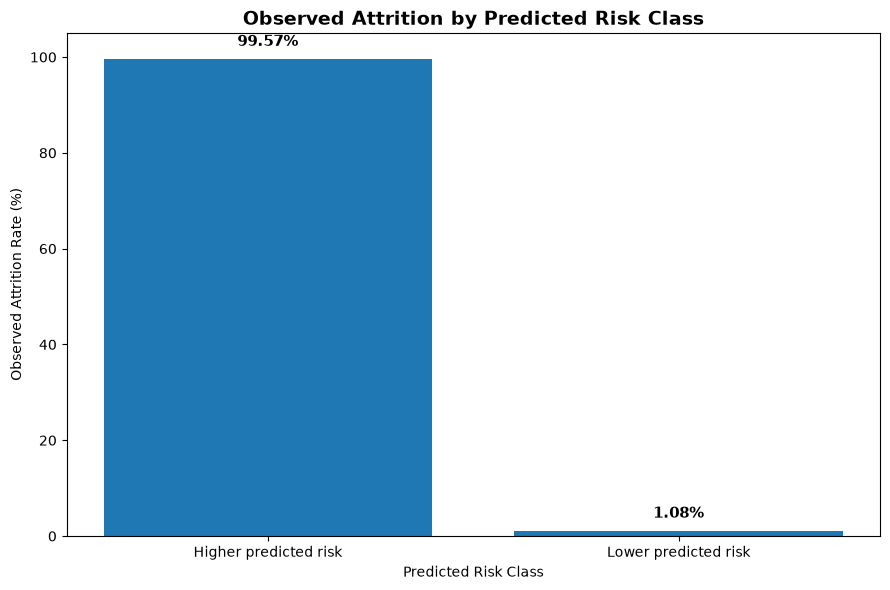

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\observed_attrition_by_risk_class.png


In [178]:
import matplotlib.pyplot as plt

# Prepare chart data
risk_chart = risk_profile_final.copy()

plt.figure(figsize=(9, 6))

bars = plt.bar(
    risk_chart["Risk_Class"],
    risk_chart["Attrition_Rate"]
)

plt.title(
    "Observed Attrition by Predicted Risk Class",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Risk Class")
plt.ylabel("Observed Attrition Rate (%)")

plt.ylim(0, 105)

for bar, value in zip(bars, risk_chart["Attrition_Rate"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

OUTPUT_PATH = (
    PROJECT_ROOT
    / "visuals"
    / "observed_attrition_by_risk_class.png"
)

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {OUTPUT_PATH}")

The model-defined higher-risk group represented 23.07% of the held-out test population and had a 99.57% observed attrition rate, compared with 1.08% among the lower-risk group.

Random Forest — Permutation Feature Importance visualization

In [118]:
# Show variables currently available in the notebook
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ColumnTransformer         ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay    type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_PATH                 WindowsPath               c:\Users\hp\Documents\Git<...>ject_dataset_combined.csv
LogisticRegression        type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OUTPUT_PATH               WindowsPath               c:\Users\hp\Documents\Git<...>trition_by_risk_class.png
OneHotEncoder             type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
PROJECT_ROOT              WindowsPath               c:\Users\hp\Documents\Git<...>ployee-attrition-analysis
Path                      type                      <class 'pathlib.Path'>
Pipeline                  ABCMeta            

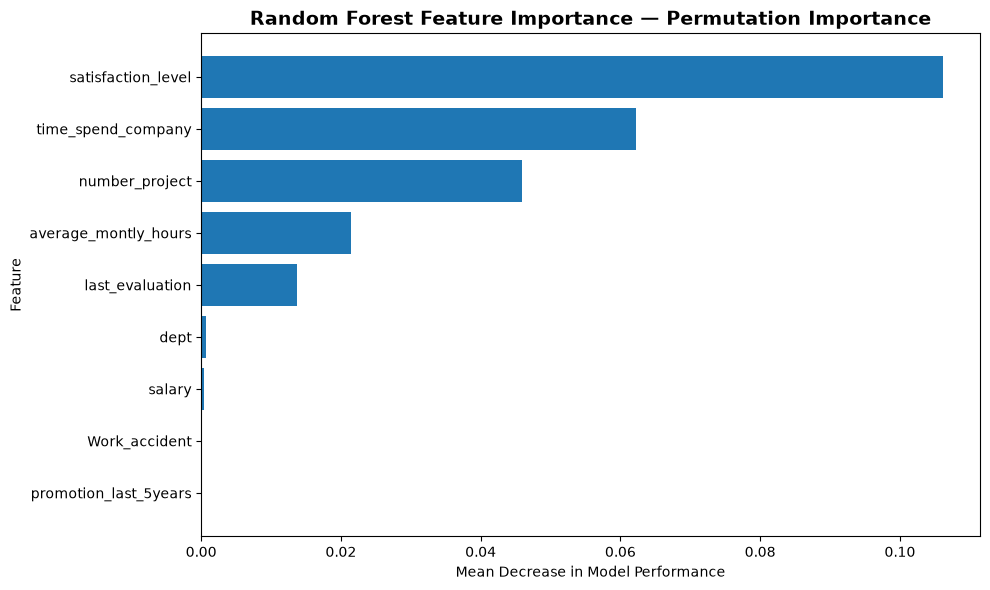

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\rf_permutation_feature_importance.png


In [119]:
# Recreate and save the Random Forest permutation importance chart

permutation_plot = permutation_df.sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    permutation_plot["Feature"],
    permutation_plot["Importance_Mean"]
)

ax.set_title(
    "Random Forest Feature Importance — Permutation Importance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Mean Decrease in Model Performance")
ax.set_ylabel("Feature")

fig.tight_layout()

OUTPUT_PATH = PROJECT_ROOT / "visuals" / "rf_permutation_feature_importance.png"

fig.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {OUTPUT_PATH}")